In [9]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler

SEED = 42
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
METRICS = {"classification": ["F1_macro", "Accuracy"], "regression": ["MAE", "RMSE", "R2"]}
PRIMARY = {"classification": "F1_macro", "regression": "MAE"}
VARIANTS = ["dummy", "sklearn", "sklearn+", "own", "own+"]

In [10]:
# читаем исходные таблицы из архивов UCI и отделяем цели от признаков
def read_uci_file(archive_name, filename, **read_options):
    url = f"https://archive.ics.uci.edu/static/public/{archive_name}"
    with urlopen(url, timeout=60) as response:
        archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        member = next(name for name in archive.namelist() if Path(name).name == filename)
        with archive.open(member) as source:
            return pd.read_csv(source, header=None, **read_options)


wifi_columns = [f"signal_{i}" for i in range(1, 8)] + ["room"]
wifi = read_uci_file(
    "422/wireless+indoor+localization.zip", "wifi_localization.txt",
    sep=r"\s+", names=wifi_columns,
)

hardware_features = ["MYCT", "MMIN", "MMAX", "CACH", "CHMIN", "CHMAX"]
hardware_columns = ["vendor", "model", *hardware_features, "PRP", "ERP"]
hardware = read_uci_file(
    "29/computer+hardware.zip", "machine.data", names=hardware_columns,
)

assert wifi.shape == (2000, 8) and hardware.shape == (209, 10)
assert set(wifi["room"]) == {1, 2, 3, 4}
assert not wifi.isna().any().any() and not hardware.isna().any().any()

DATA = {
    "classification": (wifi[wifi_columns[:-1]].to_numpy(dtype=float), wifi["room"].to_numpy()),
    "regression": (hardware[hardware_features].to_numpy(dtype=float), hardware["PRP"].to_numpy(dtype=float)),
}
for task, (X, y) in DATA.items():
    print(f"{TASK_NAMES[task]}: {X.shape[0]} объектов, {X.shape[1]} признаков")

Классификация: 2000 объектов, 7 признаков
Регрессия: 209 объектов, 6 признаков


In [11]:
# преобразуем признаки внутри каждого разбиения и считаем метрики
def transform_features(X_train, X_eval, preparation):
    if preparation == "relative":
        X_train = np.column_stack([X_train, X_train - X_train.max(axis=1, keepdims=True)])
        X_eval = np.column_stack([X_eval, X_eval - X_eval.max(axis=1, keepdims=True)])
    elif preparation == "ratios":
        def with_ratios(X):
            memory_growth = X[:, 2] / np.maximum(X[:, 1], 1)
            cache_share = X[:, 3] / np.maximum(X[:, 2], 1)
            return np.column_stack([X, memory_growth, cache_share])

        X_train, X_eval = with_ratios(X_train), with_ratios(X_eval)
    elif preparation == "log":
        X_train, X_eval = np.log1p(X_train), np.log1p(X_eval)

    if preparation in {"scale", "log", "relative"}:
        scaler = StandardScaler().fit(X_train)
        X_train, X_eval = scaler.transform(X_train), scaler.transform(X_eval)
    return X_train, X_eval


def folds(task, X, y, n_splits, seed):
    splitter_class = StratifiedKFold if task == "classification" else KFold
    return splitter_class(n_splits=n_splits, shuffle=True, random_state=seed).split(X, y)


def predict_on(model, preparation, X_train, y_train, X_eval):
    X_train, X_eval = transform_features(X_train, X_eval, preparation)
    return model.fit(X_train, y_train).predict(X_eval)


def scores(task, y, prediction):
    if task == "classification":
        return {
            "F1_macro": f1_score(y, prediction, average="macro", zero_division=0),
            "Accuracy": accuracy_score(y, prediction),
        }
    return {
        "MAE": mean_absolute_error(y, prediction),
        "RMSE": np.sqrt(mean_squared_error(y, prediction)),
        "R2": r2_score(y, prediction),
    }

## Модели

Проверяем, помогают ли сопоставимые масштабы признаков и больший вес близких соседей

In [12]:
# реализуем поиск соседей, голосование и усреднение с нуля
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor


class KNearestNeighbors:
    def __init__(self, task, n_neighbors=5, weights="uniform"):
        self.task = task
        self.n_neighbors = n_neighbors
        self.weights = weights

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    def predict(self, X):
        difference = X[:, None, :] - self.X_train[None, :, :]
        distances = np.sqrt(np.einsum("ijk,ijk->ij", difference, difference))
        neighbors = np.argsort(distances, axis=1, kind="stable")[:, :self.n_neighbors]
        nearest = np.take_along_axis(distances, neighbors, axis=1)
        targets = self.y_train[neighbors]
        weights = np.ones_like(nearest)
        if self.weights == "distance":
            zeros = nearest == 0
            weights = np.divide(1.0, nearest, out=np.zeros_like(nearest), where=~zeros)
            weights = np.where(zeros.any(axis=1, keepdims=True), zeros, weights)

        if self.task == "regression":
            return (targets * weights).sum(axis=1) / weights.sum(axis=1)
        classes = np.unique(self.y_train)
        votes = np.column_stack([((targets == label) * weights).sum(axis=1) for label in classes])
        return classes[votes.argmax(axis=1)]


def library_model(task, **params):
    estimator = KNeighborsClassifier if task == "classification" else KNeighborsRegressor
    return estimator(algorithm="brute", **params)


def own_model(task, **params):
    return KNearestNeighbors(task, **params)

In [13]:
# проверяем масштабирование, взвешивание соседей и дополнительные признаки Wi-Fi
LAB = 1
CONFIGS = {
    "classification": {
        "base": ("raw", {"n_neighbors": 5, "weights": "uniform"}),
        "scale": ("scale", {"n_neighbors": 5, "weights": "uniform"}),
        "weighted": ("raw", {"n_neighbors": 9, "weights": "distance"}),
        "scale_weighted": ("scale", {"n_neighbors": 9, "weights": "distance"}),
        "relative_weighted": ("relative", {"n_neighbors": 9, "weights": "distance"}),
    },
    "regression": {
        "base": ("raw", {"n_neighbors": 5, "weights": "uniform"}),
        "scale": ("scale", {"n_neighbors": 5, "weights": "uniform"}),
        "weighted": ("raw", {"n_neighbors": 3, "weights": "distance"}),
        "scale_weighted": ("scale", {"n_neighbors": 3, "weights": "distance"}),
        "log_weighted": ("log", {"n_neighbors": 3, "weights": "distance"}),
    },
}

## Эксперимент

Сравниваем Dummy, исходные модели (sklearn и own) и те же модели с настройками, выбранными на внутренних фолдах (sklearn+ и own+). В парных сравнениях положительное Delta означает улучшение.

In [14]:
# на каждом внешнем фолде выбираем настройки только по внутренней кросс-валидации
def choose_candidate(task, X_train, y_train, seed):
    variants = CONFIGS[task]
    inner_folds = list(folds(task, X_train, y_train, n_splits=3, seed=seed))
    means = {}
    for name, (preparation, params) in variants.items():
        values = []
        for train, valid in inner_folds:
            prediction = predict_on(
                library_model(task, **params), preparation,
                X_train[train], y_train[train], X_train[valid],
            )
            values.append(scores(task, y_train[valid], prediction)[PRIMARY[task]])
        means[name] = float(np.mean(values))
    select_best = max if task == "classification" else min
    return select_best(means, key=means.get), means


def run_experiments():
    rows, search_rows = [], []
    for task, (X, y) in DATA.items():
        for fold, (train, test) in enumerate(folds(task, X, y, n_splits=5, seed=SEED), start=1):
            X_train, y_train, X_test, y_test = X[train], y[train], X[test], y[test]
            selected, means = choose_candidate(task, X_train, y_train, SEED + fold)
            search_rows.extend(
                {"task": task, "fold": fold, "candidate": name, "score": score, "selected": name == selected}
                for name, score in means.items()
            )

            baseline_prep, baseline_params = CONFIGS[task]["base"]
            selected_prep, selected_params = CONFIGS[task][selected]
            dummy = DummyClassifier(strategy="most_frequent") if task == "classification" else DummyRegressor(strategy="median")
            experiments = {
                "dummy": (dummy, "raw"),
                "sklearn": (library_model(task, **baseline_params), baseline_prep),
                "sklearn+": (library_model(task, **selected_params), selected_prep),
                "own": (own_model(task, **baseline_params), baseline_prep),
                "own+": (own_model(task, **selected_params), selected_prep),
            }
            fold_scores = {}
            for variant, (model, preparation) in experiments.items():
                if selected == "base" and variant.endswith("+"):
                    metrics = fold_scores[variant[:-1]]
                else:
                    prediction = predict_on(model, preparation, X_train, y_train, X_test)
                    metrics = scores(task, y_test, prediction)
                fold_scores[variant] = metrics
                rows.append({"lab": LAB, "task": task, "fold": fold, "variant": variant,
                             "candidate": selected if variant.endswith("+") else "base", **metrics})
            print(f"{TASK_NAMES[task]} - фолд {fold}/5 - настройки {selected}", flush=True)
    return pd.DataFrame(rows), pd.DataFrame(search_rows)

In [15]:
# запускаем эксперимент, показываем результаты гипотез и сохраняем оценки по фолдам
results, search = run_experiments()
for task in TASK_NAMES:
    print(f"\n{TASK_NAMES[task]} - внутренний поиск по {PRIMARY[task]}")
    selection = search.loc[search["task"] == task].groupby("candidate").agg(
        cv_mean=("score", "mean"), cv_std=("score", "std"), selected_folds=("selected", "sum"),
    )
    display(selection.sort_values("cv_mean", ascending=task == "regression").round(4))

    print("Внешняя кросс-валидация - среднее и стандартное отклонение")
    report = results.loc[results["task"] == task].groupby("variant")[METRICS[task]].agg(["mean", "std"])
    display(report.reindex(VARIANTS).round(4))

output = Path("results") / f"lab_{LAB:02d}.csv"
output.parent.mkdir(exist_ok=True)
results.to_csv(output, index=False)
print(f"Файл для итогового сравнения: {output}")

Классификация - фолд 1/5 - настройки weighted
Классификация - фолд 2/5 - настройки base
Классификация - фолд 3/5 - настройки scale
Классификация - фолд 4/5 - настройки weighted
Классификация - фолд 5/5 - настройки relative_weighted
Регрессия - фолд 1/5 - настройки log_weighted
Регрессия - фолд 2/5 - настройки log_weighted
Регрессия - фолд 3/5 - настройки log_weighted
Регрессия - фолд 4/5 - настройки log_weighted
Регрессия - фолд 5/5 - настройки log_weighted

Классификация - внутренний поиск по F1_macro


,cv_mean,cv_std,selected_folds
candidate,,,
relative_weighted,0.9817,0.0019,1
base,0.9809,0.0022,1
weighted,0.9806,0.0037,2
scale,0.9795,0.0036,1
scale_weighted,0.9775,0.0024,0


Внешняя кросс-валидация - среднее и стандартное отклонение


F1_macro         Accuracy        
             mean     std     mean     std
variant                                   
dummy       0.100  0.0000    0.250  0.0000
sklearn     0.985  0.0047    0.985  0.0047
sklearn+    0.983  0.0037    0.983  0.0037
own         0.985  0.0047    0.985  0.0047
own+        0.983  0.0037    0.983  0.0037


Регрессия - внутренний поиск по MAE


,cv_mean,cv_std,selected_folds
candidate,,,
log_weighted,34.7721,1.7697,5
scale_weighted,36.2397,2.2305,0
weighted,37.9732,2.6700,0
scale,38.0823,3.4090,0
base,40.8614,4.0661,0


Внешняя кросс-валидация - среднее и стандартное отклонение


MAE               RMSE               R2        
             mean      std      mean      std    mean     std
variant                                                      
dummy     78.3256  21.2535  160.4872  63.1679 -0.1438  0.0294
sklearn   35.6695   8.3476   68.1570  27.9869  0.7945  0.0259
sklearn+  29.1439   7.0038   56.0672  30.1079  0.8648  0.0533
own       35.4695   8.4170   67.9126  28.1893  0.7963  0.0285
own+      29.2986   7.1967   56.1563  30.1367  0.8645  0.0532

Файл для итогового сравнения: results/lab_01.csv



Классификация - F1_macro
Эффект подбора sklearn: ухудшение, Delta=-0.0020, выигрышей 0/5, проигрышей 3/5
Своя реализация против исходной sklearn: без изменений, Delta=+0.0000, выигрышей 0/5, проигрышей 0/5
Своя реализация против настроенной sklearn: без изменений, Delta=+0.0000, выигрышей 0/5, проигрышей 0/5
Эффект переноса настроек на свою реализацию: ухудшение, Delta=-0.0020, выигрышей 0/5, проигрышей 3/5


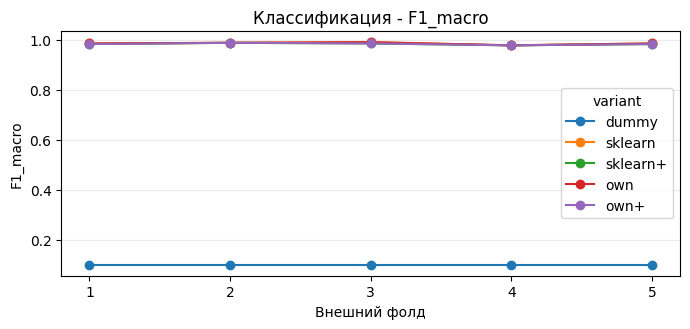


Регрессия - MAE
Эффект подбора sklearn: улучшение, Delta=+6.5256, выигрышей 5/5, проигрышей 0/5
Своя реализация против исходной sklearn: улучшение, Delta=+0.2000, выигрышей 3/5, проигрышей 1/5
Своя реализация против настроенной sklearn: ухудшение, Delta=-0.1547, выигрышей 1/5, проигрышей 2/5
Эффект переноса настроек на свою реализацию: улучшение, Delta=+6.1708, выигрышей 5/5, проигрышей 0/5


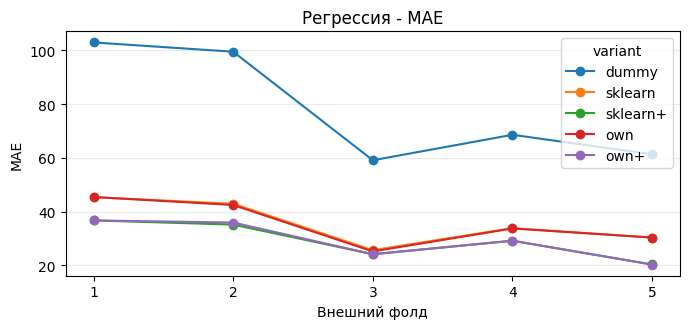

In [17]:
# считаем парные изменения метрики, чтобы сформулировать выводы по обеим задачам
comparisons = [
    ("sklearn+", "sklearn", "Эффект подбора sklearn"),
    ("own", "sklearn", "Своя реализация против исходной sklearn"),
    ("own+", "sklearn+", "Своя реализация против настроенной sklearn"),
    ("own+", "own", "Эффект переноса настроек на свою реализацию"),
]
for task in TASK_NAMES:
    metric = PRIMARY[task]
    values = results.loc[results["task"] == task].pivot(index="fold", columns="variant", values=metric)
    direction = 1 if task == "classification" else -1
    print(f"\n{TASK_NAMES[task]} - {metric}")
    for first, second, label in comparisons:
        gain = direction * (values[first] - values[second])
        mean = gain.mean()
        tendency = "улучшение" if mean > 1e-10 else "ухудшение" if mean < -1e-10 else "без изменений"
        wins = int((gain > 1e-10).sum())
        losses = int((gain < -1e-10).sum())
        print(f"{label}: {tendency}, Delta={mean:+.4f}, выигрышей {wins}/5, проигрышей {losses}/5")

    ax = values[VARIANTS].plot(marker="o", figsize=(7, 3.4), title=f"{TASK_NAMES[task]} - {metric}")
    ax.set(xlabel="Внешний фолд", ylabel=metric, xticks=values.index)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()